<a href="https://colab.research.google.com/github/kunjana30/Cloud-Project/blob/main/credit_risk_synthetic_gcp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Risk Modelling with Synthetic Data on Google Cloud
Runs in **Google Colab** (recommended) or on a **Vertex AI Workbench** instance. Run every cell top to bottom.

**Two modes, chosen in the Configuration cell:**
- `USE_GCS = False` (default): no Google Cloud project needed. You upload the CSV when asked and everything runs inside Colab.
- `USE_GCS = True`: reads the CSV from Cloud Storage, logs runs to Vertex AI Experiments, saves outputs to your bucket, and can register and deploy the model on Vertex AI.

**Golden rule:** `test_real` is only used to evaluate, never to fit generators or models.

Sections: 0 Setup and configuration, 1 Data, 2 Split, 3 Helpers, 4 Scenario A, 5 Synthetic generation, 6 Fidelity/Utility/Privacy, 7 Scenarios C and D, 8 Results, 9 SHAP, 10 Fairness, 11 Save outputs, 12 Register and deploy (optional), 13 Cleanup.

## 0. Setup

In [1]:
!pip install -q sdv imbalanced-learn xgboost fairlearn shap google-cloud-aiplatform google-cloud-storage

**If Colab shows a *Restart session* button after the install (or on Workbench: Kernel > Restart Kernel), do that, then continue from the next cell without rerunning the pip cell.**

In [2]:
import warnings; warnings.filterwarnings("ignore")
import sys, io, os
import re, time, traceback, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
from xgboost import XGBClassifier
import sdv
print("SDV version:", sdv.__version__)

SEED = 42
print("Setup complete")

SDV version: 2.1.0
Setup complete


### Configuration
Leave `USE_GCS = False` to run without any Google Cloud project. Set it to `True` and fill in the three values only if you have created a project and bucket.

In [3]:
IN_COLAB = "google.colab" in sys.modules

USE_GCS    = True                           # Set to False to run in local mode using your uploaded CSV
PROJECT_ID = "project-cddb5108-9346-41b5-bcd"    # <-- edit this line (the ID, not the project name)
REGION     = "asia-south1"                   # same region as your bucket
BUCKET     = "credit-risk-synth-kunjana-2026"   # <-- edit this line (name only, without gs://)
DATA_FILE  = "data/default_of_credit_card_clients.csv"   # path inside the bucket
LOCAL_CSV  = "default of credit card clients.csv"   # Updated to match the file present in your workspace

CLOUD_READY = False
USE_VERTEX_EXPERIMENTS = False
aiplatform = None

if USE_GCS:
    # Removed the template-string assertion to allow direct connection using the configured project-id
    assert PROJECT_ID.strip() and BUCKET.strip(), "Edit PROJECT_ID and BUCKET first."
    if IN_COLAB:
        from google.colab import auth
        auth.authenticate_user()             # a sign-in popup appears: allow access
    try:
        from google.cloud import aiplatform
        aiplatform.init(project=PROJECT_ID, location=REGION, staging_bucket=f"gs://{BUCKET}")
        CLOUD_READY = True
        try:
            aiplatform.init(project=PROJECT_ID, location=REGION, staging_bucket=f"gs://{BUCKET}",
                            experiment="credit-risk-synthetic")
            USE_VERTEX_EXPERIMENTS = True
        except Exception as e:
            print("Vertex Experiments unavailable, continuing without it:", str(e)[:120])
        print("Connected to Google Cloud project:", PROJECT_ID, "| region:", REGION)
    except Exception as e:
        print("Google Cloud connection failed, continuing in local mode:", str(e)[:200])
        USE_GCS = False
else:
    print("Running in local mode (no Google Cloud project needed). Colab:", IN_COLAB)

Connected to Google Cloud project: project-cddb5108-9346-41b5-bcd | region: asia-south1


## 1. Load data
In local mode in Colab, click **Choose files** and select `default_of_credit_card_clients.csv`. With `USE_GCS = True` it is read from your bucket.

In [7]:
if USE_GCS:
    from google.cloud import storage
    client = storage.Client(project=PROJECT_ID)
    bucket_obj = client.bucket(BUCKET)

    # Try loading the original DATA_FILE path, then try with spaces, then root names
    try:
        raw_bytes = bucket_obj.blob(DATA_FILE).download_as_bytes()
    except Exception:
        try:
            # Try the exact name with spaces from LOCAL_CSV
            raw_bytes = bucket_obj.blob(LOCAL_CSV).download_as_bytes()
        except Exception:
            try:
                # Try root folder location without 'data/' path
                filename_only = DATA_FILE.split('/')[-1]
                raw_bytes = bucket_obj.blob(filename_only).download_as_bytes()
            except Exception:
                print("GCS download failed, falling back to local file path...")
                raw_bytes = open(LOCAL_CSV, "rb").read()
elif IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    raw_bytes = uploaded[next(iter(uploaded))]
else:
    raw_bytes = open(LOCAL_CSV, "rb").read()

df = pd.read_csv(io.BytesIO(raw_bytes))
if "X1" in df.columns:                     # UCI file: first row is X1..X23,Y, real names are in row 2
    df = pd.read_csv(io.BytesIO(raw_bytes), header=1)

df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
df = df.rename(columns={"default payment next month": "default",
                        "default.payment.next.month": "default", "PAY_1": "PAY_0"})
df = df.drop(columns=["ID"], errors="ignore")
df = df.apply(pd.to_numeric, errors="raise")

expected = ["LIMIT_BAL","SEX","EDUCATION","MARRIAGE","AGE","PAY_0","default"]
missing = [c for c in expected if c not in df.columns]
assert not missing, f"Missing columns {missing}. Found: {list(df.columns)}"

print(df.shape, "| nulls:", int(df.isnull().sum().sum()))
print(df["default"].value_counts(normalize=True).round(3))
df.head()

(30000, 24) | nulls: 0
default
0    0.779
1    0.221
Name: proportion, dtype: float64


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


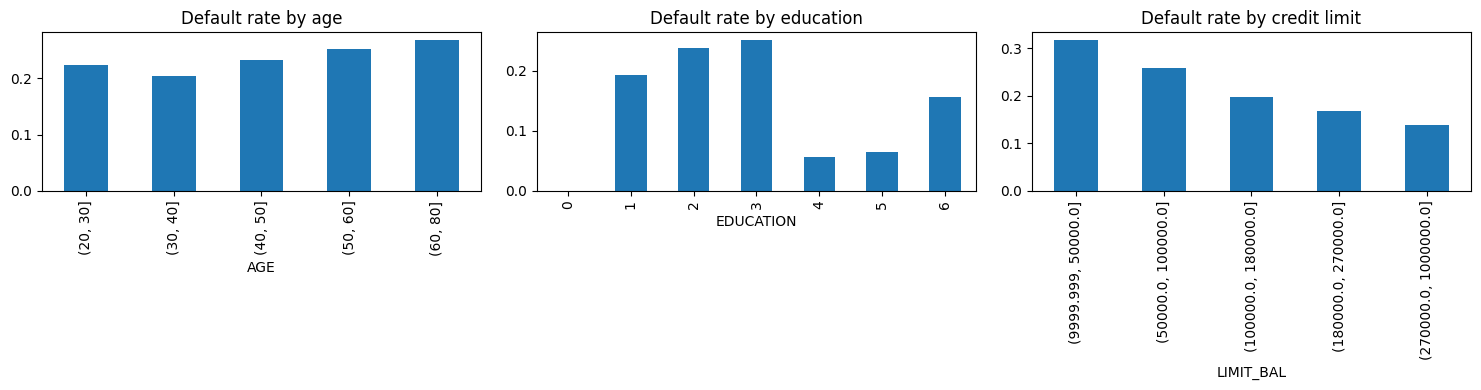

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby(pd.cut(df["AGE"], [20,30,40,50,60,80]))["default"].mean().plot.bar(ax=ax[0], title="Default rate by age")
df.groupby("EDUCATION")["default"].mean().plot.bar(ax=ax[1], title="Default rate by education")
df.groupby(pd.qcut(df["LIMIT_BAL"], 5, duplicates="drop"))["default"].mean().plot.bar(ax=ax[2], title="Default rate by credit limit")
plt.tight_layout(); plt.show()

## 2. Split (test set is locked away)

In [9]:
train_real, test_real = train_test_split(df, test_size=0.3, stratify=df["default"], random_state=SEED)
train_real = train_real.reset_index(drop=True); test_real = test_real.reset_index(drop=True)
features = [c for c in df.columns if c != "default"]
X_test, y_test = test_real[features], test_real["default"]
print(train_real.shape, test_real.shape)

(21000, 24) (9000, 24)


## 3. Evaluation helpers

In [10]:
def evaluate(model, X, y):
    p = model.predict_proba(X)[:, 1]
    pred = (p >= 0.5).astype(int)
    auc = roc_auc_score(y, p)
    return {"roc_auc": auc, "gini": 2*auc-1, "pr_auc": average_precision_score(y, p),
            "ks": ks_2samp(p[y==1], p[y==0]).statistic,
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred)}

def make_models():
    return {
        "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "rf": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
        "xgb": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, eval_metric="logloss", random_state=SEED),
    }

fitted = {}   # (scenario, model_name) -> fitted model

def log_vertex(scenario, name, params, metrics):
    """Log one run to Vertex AI Experiments. Never lets tracking problems stop the project."""
    if not (CLOUD_READY and USE_VERTEX_EXPERIMENTS): return
    try:
        run_id = re.sub(r"[^a-z0-9-]", "-", f"{scenario}-{name}-{int(time.time())}".lower())
        aiplatform.start_run(run=run_id)
        aiplatform.log_params(params)
        aiplatform.log_metrics({k: float(v) for k, v in metrics.items()})
        aiplatform.end_run()
    except Exception as e:
        print("Vertex tracking skipped:", str(e)[:120])
        try: aiplatform.end_run()
        except Exception: pass

def run_scenario(scenario, X_train, y_train):
    rows = []
    for name, model in make_models().items():
        t0 = time.time(); model.fit(X_train, y_train); secs = time.time() - t0
        m = evaluate(model, X_test, y_test)
        log_vertex(scenario, name, {"scenario": scenario, "model": name, "n_train": len(X_train)},
                   {**m, "train_seconds": secs})
        fitted[(scenario, name)] = model
        rows.append({"scenario": scenario, "model": name, **m, "train_seconds": secs})
    return pd.DataFrame(rows)

## 4. Scenario A: real data only (baseline)

In [11]:
res_A = run_scenario("A_real_only", train_real[features], train_real["default"])
res_A.round(4)

,scenario,model,roc_auc,gini,pr_auc,ks,precision,recall,f1,train_seconds
0,A_real_only,logreg,0.7150,0.4301,0.4978,0.3751,0.6973,0.2361,0.3527,0.2122
1,A_real_only,rf,0.7596,0.5192,0.5292,0.4019,0.6261,0.3666,0.4625,14.9499
2,A_real_only,xgb,0.7788,0.5576,0.5514,0.4277,0.6664,0.3551,0.4633,0.8955


## 5. Generate synthetic data (fit on `train_real` only)
### 5a. Metadata (works on SDV 1.x and 2.x)

In [12]:
from sdv.single_table import GaussianCopulaSynthesizer, CTGANSynthesizer, TVAESynthesizer
from sdv.sampling import Condition

cat_cols = ["SEX", "EDUCATION", "MARRIAGE", "default"]
TABLE = "credit"

def build_metadata(data):
    """Try every metadata API used across SDV versions. Returns (metadata, uses_table_name)."""
    errors = []
    try:
        from sdv.metadata import Metadata
        if hasattr(Metadata, "detect_from_dataframes"):          # SDV 1.17+ / 2.x
            return Metadata.detect_from_dataframes(data={TABLE: data}), True
        if hasattr(Metadata, "detect_from_dataframe"):
            return Metadata.detect_from_dataframe(data=data, table_name=TABLE), True
        errors.append("Metadata class has no detect_from_dataframe(s)")
    except Exception as e:
        errors.append(f"Metadata: {e!r}")
    try:
        from sdv.metadata import SingleTableMetadata               # SDV 1.x
        m = SingleTableMetadata()
        m.detect_from_dataframe(data)
        return m, False
    except Exception as e:
        errors.append(f"SingleTableMetadata: {e!r}")
    raise RuntimeError("Could not build metadata: " + " | ".join(errors))

metadata, uses_table_name = build_metadata(train_real)

for c in cat_cols:
    if uses_table_name:
        metadata.update_column(table_name=TABLE, column_name=c, sdtype="categorical")
    else:
        metadata.update_column(column_name=c, sdtype="categorical")
metadata.validate()
print("Metadata OK | SDV", sdv.__version__)

Metadata OK | SDV 2.1.0


### 5b. Train the generators
`EPOCHS = 100` is a good balance on Colab. Raise to 300 only on a GPU runtime. Each generator is wrapped so one failure does not stop the rest.

In [13]:
EPOCHS = 40
TABLE = "credit"

def as_df(x):
    """Newer SDV versions may return {table_name: DataFrame}; always give back a DataFrame."""
    return next(iter(x.values())) if isinstance(x, dict) else x

def fit_any(synth, data):
    """Newer SDV wants fit({table: df}); older wants fit(df). Try the plain form first."""
    try:
        synth.fit(data)
    except Exception as e:
        if "dictionary" in str(e) or "dict" in str(e).lower():
            synth.fit({TABLE: data})
        else:
            raise

synthesizers = {
    "gaussian_copula": GaussianCopulaSynthesizer(metadata),
    "ctgan": CTGANSynthesizer(metadata, epochs=EPOCHS, batch_size=1000, verbose=True),
    "tvae": TVAESynthesizer(metadata, epochs=EPOCHS, batch_size=1000),
}

def clean_synth(syn):
    """Round whole-number columns, keep values in the real range, restore dtypes."""
    syn = syn.copy()
    for c in df.columns:
        if df[c].dtype.kind in "iu":
            syn[c] = syn[c].astype(float).round().clip(df[c].min(), df[c].max()).astype(df[c].dtype)
        else:
            syn[c] = syn[c].astype(df[c].dtype)
    return syn[df.columns]

synthetic, gen_seconds = {}, {}
for name, s in synthesizers.items():
    try:
        t0 = time.time()
        fit_any(s, train_real)
        synthetic[name] = clean_synth(as_df(s.sample(num_rows=len(train_real))))
        gen_seconds[name] = time.time() - t0
        synthetic[name].to_csv(f"synthetic_{name}.csv", index=False)
        print(f"{name}: done in {gen_seconds[name]:.0f}s")
    except Exception:
        print(f"--- {name} FAILED ---"); traceback.print_exc()

assert len(synthetic) > 0, "No generator succeeded; see the errors above."
print("Generators available:", list(synthetic))

gaussian_copula: done in 16s


Gen. (-00.66) | Discrim. (+00.05): 100%|██████████| 40/40 [03:07<00:00,  4.68s/it]


ctgan: done in 276s
tvae: done in 124s
Generators available: ['gaussian_copula', 'ctgan', 'tvae']


## 6. Evaluate synthetic data
### 6a. Fidelity

In [14]:
import numpy as np
from scipy.stats import ks_2samp

def _own_quality(real, syn):
    """Fallback fidelity score (0 to 1): column-shape similarity + correlation similarity."""
    shapes = []
    for c in real.columns:
        if c in cat_cols or real[c].nunique() <= 12:
            p = real[c].value_counts(normalize=True)
            q = syn[c].value_counts(normalize=True)
            idx = p.index.union(q.index)
            tv = 0.5 * np.abs(p.reindex(idx, fill_value=0) - q.reindex(idx, fill_value=0)).sum()
            shapes.append(1 - tv)
        else:
            shapes.append(1 - ks_2samp(real[c], syn[c]).statistic)
    corr_gap = np.abs(real.corr().values - syn.corr().fillna(0).values)
    pair_trend = 1 - np.nanmean(corr_gap) / 2
    return float((np.mean(shapes) + pair_trend) / 2)

def quality_score(real, syn):
    # 1) SDV's own evaluator (module location differs between versions)
    for mod in ("sdv.evaluation.single_table", "sdv.evaluation"):
        try:
            evaluate_quality = __import__(mod, fromlist=["evaluate_quality"]).evaluate_quality
            try:
                return evaluate_quality(real, syn, metadata, verbose=False).get_score()
            except Exception:
                return evaluate_quality({TABLE: real}, {TABLE: syn}, metadata, verbose=False).get_score()
        except Exception:
            pass
    # 2) SDMetrics directly
    try:
        from sdmetrics.reports.single_table import QualityReport
        md = metadata.to_dict()
        md = md["tables"][TABLE] if "tables" in md else md
        rep = QualityReport(); rep.generate(real, syn, md, verbose=False)
        return rep.get_score()
    except Exception:
        pass
    # 3) our own approximate score
    return _own_quality(real, syn)

quality = {}
for name, syn in synthetic.items():
    quality[name] = quality_score(train_real, syn)
pd.Series(quality, name="quality_score").round(4)

,quality_score
gaussian_copula,0.8437
ctgan,0.6981
tvae,0.7860


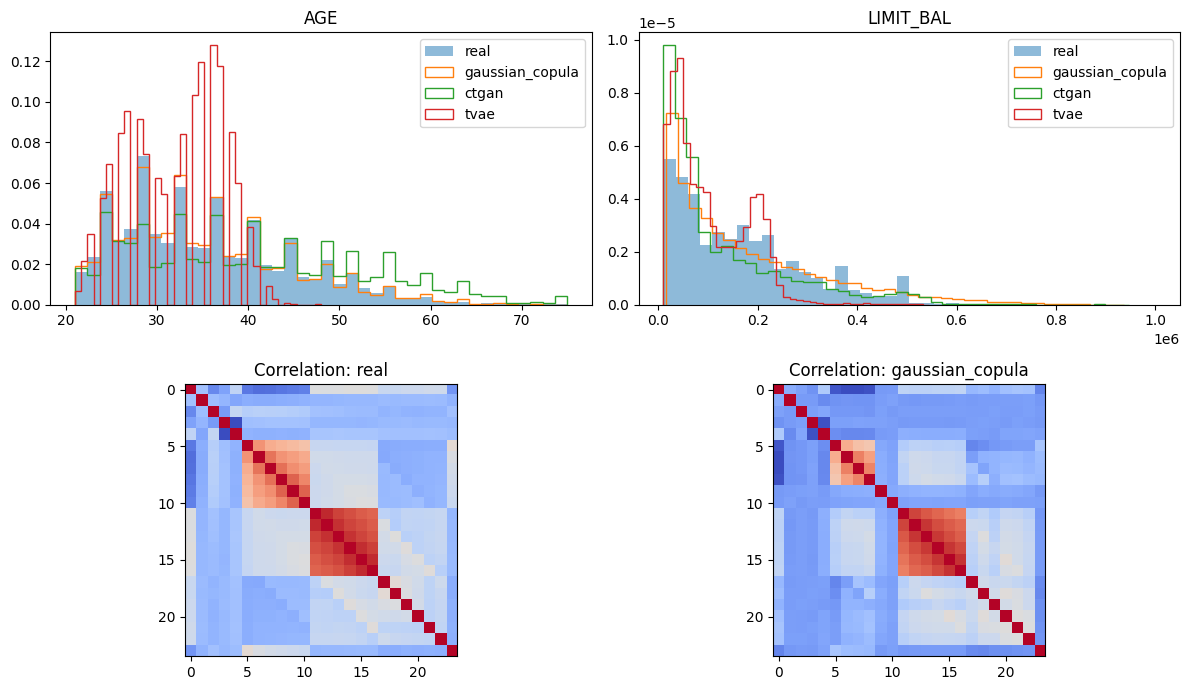

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for i, col in enumerate(["AGE", "LIMIT_BAL"]):
    ax[0][i].hist(train_real[col], bins=40, alpha=.5, density=True, label="real")
    for n, s in synthetic.items(): ax[0][i].hist(s[col], bins=40, histtype="step", density=True, label=n)
    ax[0][i].set_title(col); ax[0][i].legend()
ax[1][0].imshow(train_real.corr(), cmap="coolwarm"); ax[1][0].set_title("Correlation: real")
best_fid = max(quality, key=quality.get)
ax[1][1].imshow(synthetic[best_fid].corr(), cmap="coolwarm"); ax[1][1].set_title(f"Correlation: {best_fid}")
plt.tight_layout(); plt.show()

### 6b. Utility: Scenario B (Train on Synthetic, Test on Real)

In [16]:
res_B = pd.concat([run_scenario(f"B_synthetic_only_{n}", s[features], s["default"])
                   for n, s in synthetic.items()], ignore_index=True)
res_B.round(4)

,scenario,model,roc_auc,gini,pr_auc,ks,precision,recall,f1,train_seconds
0,B_synthetic_only_gaussian_copula,logreg,0.7174,0.4348,0.4745,0.3360,0.7442,0.0321,0.0616,0.1597
1,B_synthetic_only_gaussian_copula,rf,0.6732,0.3464,0.3830,0.2716,0.6964,0.0588,0.1084,18.6850
2,B_synthetic_only_gaussian_copula,xgb,0.7027,0.4055,0.4177,0.3243,0.5241,0.1421,0.2236,0.8815
3,B_synthetic_only_ctgan,logreg,0.5638,0.1276,0.2675,0.1016,0.0000,0.0000,0.0000,0.0546
4,B_synthetic_only_ctgan,rf,0.5602,0.1203,0.2493,0.1336,0.3636,0.0161,0.0308,17.4902
5,B_synthetic_only_ctgan,xgb,0.5701,0.1402,0.2447,0.1319,0.1880,0.0392,0.0648,0.9202
6,B_synthetic_only_tvae,logreg,0.7070,0.4140,0.4767,0.3328,0.6783,0.2245,0.3374,0.1823
7,B_synthetic_only_tvae,rf,0.7248,0.4496,0.4728,0.3592,0.6655,0.1929,0.2991,9.4910
8,B_synthetic_only_tvae,xgb,0.7351,0.4702,0.4751,0.3764,0.6470,0.1979,0.3031,0.9019


### 6c. Privacy: distance to closest record (DCR)
Synthetic rows should not be *closer* to the training set than genuinely new real customers (the test set).

In [17]:
scaler = StandardScaler().fit(train_real[features])
nn = NearestNeighbors(n_neighbors=1).fit(scaler.transform(train_real[features]))

def dcr(frame):
    d, _ = nn.kneighbors(scaler.transform(frame[features]))
    return d.ravel()

priv = {"real_test (baseline)": dcr(test_real)}
for n, s in synthetic.items(): priv[n] = dcr(s)
privacy = pd.DataFrame({k: {"median_dcr": np.median(v), "p5_dcr": np.percentile(v, 5),
                            "exact_copies": int((v < 1e-6).sum())} for k, v in priv.items()}).T
privacy.round(4)

,median_dcr,p5_dcr,exact_copies
real_test (baseline),0.8002,0.1529,22.0
gaussian_copula,2.5551,1.5405,0.0
ctgan,2.8863,1.1984,0.0
tvae,0.5159,0.1789,0.0


## 7. Scenarios C and D
C: real data plus synthetic defaulters from the best generator. D: real data with SMOTE.

`best_gen` is chosen automatically by highest fidelity score. Override it by setting e.g. `best_gen = "ctgan"`.

In [18]:
from imblearn.over_sampling import SMOTE

best_gen = max(quality, key=quality.get)
print("Using generator:", best_gen)

n_extra = int((train_real["default"] == 0).sum() - (train_real["default"] == 1).sum())

def sample_defaulters(synth, n):
    try:
        out = as_df(synth.sample_from_conditions(
            conditions=[Condition(num_rows=n, column_values={"default": 1})]))
    except Exception as e:
        print("Conditional sampling failed, using rejection sampling:", str(e)[:120])
        parts, got = [], 0
        for _ in range(20):
            s = as_df(synth.sample(num_rows=n * 4))
            s = s[s["default"].astype(int) == 1]
            parts.append(s); got += len(s)
            if got >= n: break
        out = pd.concat(parts).head(n)
    return clean_synth(out)

extra = sample_defaulters(synthesizers[best_gen], n_extra)
print("Extra synthetic defaulters:", len(extra))

aug = pd.concat([train_real, extra], ignore_index=True)
res_C = run_scenario("C_real_plus_synth", aug[features], aug["default"])

X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(train_real[features], train_real["default"])
res_D = run_scenario("D_real_SMOTE", X_sm, y_sm)
pd.concat([res_C, res_D]).round(4)

Using generator: gaussian_copula


Sampling conditions: 100%|██████████| 11710/11710 [00:00<00:00, 11953.08it/s]


Extra synthetic defaulters: 11710


,scenario,model,roc_auc,gini,pr_auc,ks,precision,recall,f1,train_seconds
0,C_real_plus_synth,logreg,0.6905,0.3810,0.4073,0.2999,0.3916,0.5264,0.4491,0.2534
1,C_real_plus_synth,rf,0.7521,0.5041,0.5186,0.3927,0.6077,0.3983,0.4812,20.6505
2,C_real_plus_synth,xgb,0.7754,0.5508,0.5361,0.4272,0.6270,0.3807,0.4738,3.4023
0,D_real_SMOTE,logreg,0.6934,0.3868,0.4466,0.3088,0.3724,0.5856,0.4553,0.2379
1,D_real_SMOTE,rf,0.7514,0.5028,0.4961,0.3800,0.5131,0.4922,0.5024,21.4202
2,D_real_SMOTE,xgb,0.7512,0.5025,0.5107,0.3829,0.4837,0.5294,0.5055,1.1865


## 8. Results

,scenario,model,roc_auc,gini,pr_auc,ks,precision,recall,f1,train_seconds
2,A_real_only,xgb,0.7788,0.5576,0.5514,0.4277,0.6664,0.3551,0.4633,0.8955
14,C_real_plus_synth,xgb,0.7754,0.5508,0.5361,0.4272,0.6270,0.3807,0.4738,3.4023
1,A_real_only,rf,0.7596,0.5192,0.5292,0.4019,0.6261,0.3666,0.4625,14.9499
13,C_real_plus_synth,rf,0.7521,0.5041,0.5186,0.3927,0.6077,0.3983,0.4812,20.6505
16,D_real_SMOTE,rf,0.7514,0.5028,0.4961,0.3800,0.5131,0.4922,0.5024,21.4202
17,D_real_SMOTE,xgb,0.7512,0.5025,0.5107,0.3829,0.4837,0.5294,0.5055,1.1865
11,B_synthetic_only_tvae,xgb,0.7351,0.4702,0.4751,0.3764,0.6470,0.1979,0.3031,0.9019
10,B_synthetic_only_tvae,rf,0.7248,0.4496,0.4728,0.3592,0.6655,0.1929,0.2991,9.4910
3,B_synthetic_only_gaussian_copula,logreg,0.7174,0.4348,0.4745,0.3360,0.7442,0.0321,0.0616,0.1597
0,A_real_only,logreg,0.7150,0.4301,0.4978,0.3751,0.6973,0.2361,0.3527,0.2122


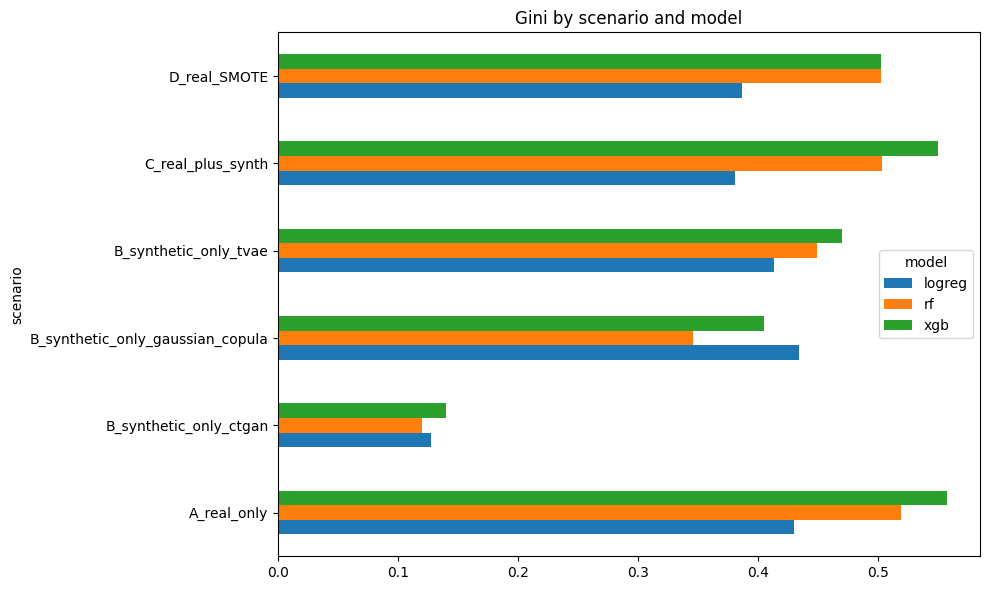

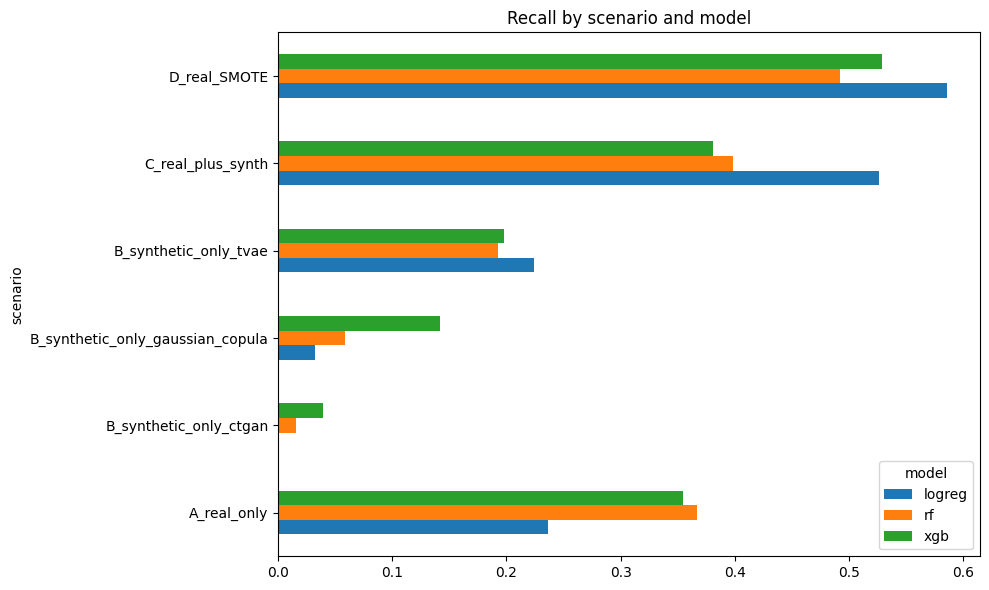

In [19]:
final = pd.concat([res_A, res_B, res_C, res_D], ignore_index=True)
final.to_csv("all_results.csv", index=False)
display(final.sort_values("gini", ascending=False).round(4))

final.pivot(index="scenario", columns="model", values="gini").plot.barh(figsize=(10, 6), title="Gini by scenario and model")
plt.tight_layout(); plt.show()
final.pivot(index="scenario", columns="model", values="recall").plot.barh(figsize=(10, 6), title="Recall by scenario and model")
plt.tight_layout(); plt.show()

In [20]:
# Optional cost estimate (compare against an Azure VM price such as ~0.23 USD/hour for DS3_v2)
PRICE_PER_HOUR = 0.23
cost = final.groupby("scenario")["train_seconds"].sum().to_frame("train_seconds")
cost["est_cost_usd"] = cost["train_seconds"] / 3600 * PRICE_PER_HOUR
gen = pd.Series(gen_seconds, name="generation_seconds").to_frame()
gen["est_cost_usd"] = gen["generation_seconds"] / 3600 * PRICE_PER_HOUR
display(cost.round(4)); display(gen.round(4))

,train_seconds,est_cost_usd
scenario,,
A_real_only,16.0576,0.0010
B_synthetic_only_ctgan,18.4651,0.0012
B_synthetic_only_gaussian_copula,19.7262,0.0013
B_synthetic_only_tvae,10.5752,0.0007
C_real_plus_synth,24.3061,0.0016
D_real_SMOTE,22.8445,0.0015


,generation_seconds,est_cost_usd
gaussian_copula,15.8656,0.0010
ctgan,276.2361,0.0176
tvae,124.1757,0.0079


## 9. Explainability (SHAP)
The best tree-based model (Random Forest or XGBoost) is picked automatically by Gini.

Best tree model: ('A_real_only', 'xgb')


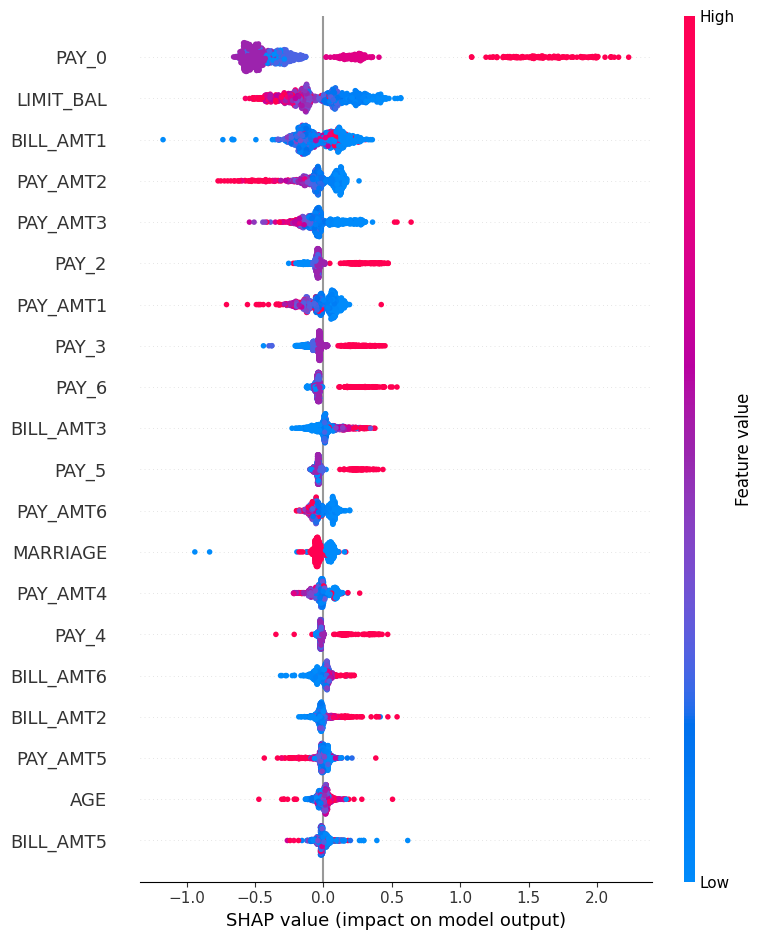

In [21]:
import shap
tree_rows = final[final["model"].isin(["rf", "xgb"])].sort_values("gini", ascending=False)
BEST = (tree_rows.iloc[0]["scenario"], tree_rows.iloc[0]["model"])
print("Best tree model:", BEST)
best_model = fitted[BEST]

sample = X_test.sample(1000, random_state=1)
sv = shap.TreeExplainer(best_model).shap_values(sample)
if isinstance(sv, list): sv = sv[1]            # older shap, random forest
elif getattr(sv, "ndim", 2) == 3: sv = sv[:, :, 1]
shap.summary_plot(sv, sample)

## 10. Fairness (Fairlearn)
Compares sex-based gaps for the real-only model, the best model, and the synthetic-only model.

In [22]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate

def fairness(model, label):
    pred = model.predict(X_test)
    mf = MetricFrame(metrics={"selection_rate": selection_rate, "recall": true_positive_rate},
                     y_true=y_test, y_pred=pred, sensitive_features=test_real["SEX"])
    print(f"--- {label} ---"); print(mf.by_group.round(4)); print("max gap:"); print(mf.difference().round(4)); print()

fairness(fitted[("A_real_only", BEST[1])], f"Real only ({BEST[1]})")
fairness(best_model, f"{BEST[0]} ({BEST[1]})")
fairness(fitted[(f"B_synthetic_only_{best_gen}", BEST[1])], f"Synthetic only: {best_gen} ({BEST[1]})")

--- Real only (xgb) ---
     selection_rate  recall
SEX                        
1            0.1235  0.3447
2            0.1142  0.3628
max gap:
selection_rate    0.0093
recall            0.0181
dtype: float64

--- A_real_only (xgb) ---
     selection_rate  recall
SEX                        
1            0.1235  0.3447
2            0.1142  0.3628
max gap:
selection_rate    0.0093
recall            0.0181
dtype: float64

--- Synthetic only: gaussian_copula (xgb) ---
     selection_rate  recall
SEX                        
1            0.0620  0.1459
2            0.0587  0.1394
max gap:
selection_rate    0.0034
recall            0.0065
dtype: float64



## 11. Save the model and results
Always saved in the notebook's local files. If `USE_GCS = True` they are also uploaded to your bucket. In Colab they are downloaded to your computer.

In [23]:
import joblib
import os

# Ensure clean serialization for compatibility with older XGBoost containers (1.7)
if BEST[1] == "xgb":
    booster = best_model.get_booster()
    # Completely strip feature names and types from the booster object
    booster.feature_names = None
    booster.feature_types = None
    # Save in standard raw booster bst format
    booster.save_model("model.bst")
    # Also save as joblib for local fallback if needed
    joblib.dump(best_model, "model.joblib")
else:
    joblib.dump(best_model, "model.joblib")

final.to_csv("all_results.csv", index=False)

if USE_GCS and CLOUD_READY:
    from google.cloud import storage
    bucket = storage.Client(project=PROJECT_ID).bucket(BUCKET)
    if BEST[1] == "xgb":
        bucket.blob("model/model.bst").upload_from_filename("model.bst")
        # Clean up any residual model.joblib in GCS folder to prevent container confusion
        try:
            bucket.blob("model/model.joblib").delete()
        except Exception:
            pass
    else:
        bucket.blob("model/model.joblib").upload_from_filename("model.joblib")

    bucket.blob("results/all_results.csv").upload_from_filename("all_results.csv")
    for n in synthetic:
        bucket.blob(f"synthetic/synthetic_{n}.csv").upload_from_filename(f"synthetic_{n}.csv")
    print(f"Saved to gs://{BUCKET}/ (model/, results/, synthetic/)")
else:
    print("Saved locally: model.bst/joblib, all_results.csv, synthetic_*.csv")

if IN_COLAB:
    from google.colab import files
    try:
        if os.path.exists("model.bst"):
            files.download("model.bst")
        else:
            files.download("model.joblib")
        files.download("all_results.csv")
    except Exception:
        pass

Saved to gs://credit-risk-synth-kunjana-2026/ (model/, results/, synthetic/)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
vertex_model, endpoint = None, None

if USE_GCS and CLOUD_READY:
    import sklearn, xgboost
    # Fixed the typo here: changed sklearn.__version" to sklearn.__version__
    fw, ver = ("xgboost", xgboost.__version__) if BEST[1] == "xgb" else ("sklearn", sklearn.__version__)
    major, minor = ver.split(".")[:2]
    region_prefix = "asia" if REGION.startswith("asia") else ("europe" if REGION.startswith("europe") else "us")

    # Use a supported prebuilt container for XGBoost since 3.x is not yet available in prebuilt prediction images
    IMAGE_OVERRIDE = f"{region_prefix}-docker.pkg.dev/vertex-ai/prediction/xgboost-cpu.1-7:latest" if BEST[1] == "xgb" else None
    IMAGE = IMAGE_OVERRIDE or f"{region_prefix}-docker.pkg.dev/vertex-ai/prediction/{fw}-cpu.{major}-{minor}:latest"
    print("Trained with", fw, ver, "| container:", IMAGE)
    try:
        vertex_model = aiplatform.Model.upload(
            display_name="credit-default-model-clean",
            artifact_uri=f"gs://{BUCKET}/model/",
            serving_container_image_uri=IMAGE)
        print("Registered:", vertex_model.resource_name)
    except Exception as e:
        print("Model registration failed (set IMAGE_OVERRIDE to a matching container):", str(e)[:300])
else:
    print("Skipped: set USE_GCS = True to register the model on Vertex AI.")

Trained with xgboost 3.4.1 | container: asia-docker.pkg.dev/vertex-ai/prediction/xgboost-cpu.1-7:latest
Registered: projects/519137326094/locations/asia-south1/models/1468819991359913984


In [25]:
DEPLOY_ENDPOINT = True

if DEPLOY_ENDPOINT and vertex_model is not None:
    print(f"Deploying model {vertex_model.display_name} to endpoint...")
    endpoint = vertex_model.deploy(
        machine_type="n1-standard-2",
        min_replica_count=1,
        max_replica_count=1
    )
    print("Endpoint deployment complete!")
    print("Endpoint:", endpoint.resource_name)
else:
    print("Endpoint not deployed (DEPLOY_ENDPOINT is False or the model was not registered).")

Deploying model credit-default-model-clean to endpoint...
Endpoint deployment complete!
Endpoint: projects/519137326094/locations/asia-south1/endpoints/5818661713678958592


In [26]:
if endpoint is not None:
    # Format instances as a 2D list of values to satisfy the schema-free booster container
    sample = X_test.head(3).values.tolist()
    print("Predictions:", endpoint.predict(instances=sample).predictions)
    print("Actual:     ", y_test.head(3).tolist())
else:
    # local check that the saved model works
    print("Local predictions:", best_model.predict(X_test.head(3)).tolist())
    print("Actual:           ", y_test.head(3).tolist())

Predictions: [0.1920175850391388, 0.7237401008605957, 0.2557714879512787]
Actual:      [0, 1, 0]


## 12. Register the model and deploy it on Vertex AI (optional)
Runs only when `USE_GCS = True`. Vertex AI serves scikit-learn and XGBoost models with **prebuilt containers**, and the container version must match the library version used for training.

The cell below guesses the container address from your installed version. If the upload fails, open the Google documentation page *"Prebuilt containers for inference"*, pick the scikit-learn or XGBoost image closest to the version printed, and set `IMAGE_OVERRIDE`.

In [27]:
vertex_model, endpoint = None, None

if USE_GCS and CLOUD_READY:
    from google.cloud import storage
    import sklearn, xgboost

    # 1. Cleanly upload the raw, sanitized booster model to GCS
    bucket = storage.Client(project=PROJECT_ID).bucket(BUCKET)
    if BEST[1] == "xgb":
        blob = bucket.blob("model/model.bst")
        blob.upload_from_filename("model.bst")
        print("Sanitized model.bst re-uploaded to GCS.")
    else:
        blob = bucket.blob("model/model.joblib")
        blob.upload_from_filename("model.joblib")
        print("Sanitized model.joblib re-uploaded to GCS.")

    # 2. Select the matching serving container image
    fw, ver = ("xgboost", xgboost.__version__) if BEST[1] == "xgb" else ("sklearn", sklearn.__version__)
    region_prefix = "asia" if REGION.startswith("asia") else ("europe" if REGION.startswith("europe") else "us")
    IMAGE = f"{region_prefix}-docker.pkg.dev/vertex-ai/prediction/xgboost-cpu.1-7:latest" if BEST[1] == "xgb" else f"{region_prefix}-docker.pkg.dev/vertex-ai/prediction/{fw}-cpu.1-7:latest"

    print("Registering model with container:", IMAGE)
    try:
        vertex_model = aiplatform.Model.upload(
            display_name="credit-default-model-clean-booster",
            artifact_uri=f"gs://{BUCKET}/model/",
            serving_container_image_uri=IMAGE
        )
        print("Successfully registered clean booster model:", vertex_model.resource_name)
    except Exception as e:
        print("Model registration failed:", str(e))
else:
    print("Skipped registration.")

Sanitized model.bst re-uploaded to GCS.
Registering model with container: asia-docker.pkg.dev/vertex-ai/prediction/xgboost-cpu.1-7:latest
Successfully registered clean booster model: projects/519137326094/locations/asia-south1/models/3596770815292473344


**Deploying creates a billed endpoint.** Set `DEPLOY_ENDPOINT = True` only when you are ready to demo, and delete the endpoint afterwards (Section 13). It takes 10 to 20 minutes.

In [29]:
DEPLOY_ENDPOINT = True

if DEPLOY_ENDPOINT and vertex_model is not None:
    print(f"Deploying clean booster model {vertex_model.display_name} ({vertex_model.resource_name}) to endpoint...")
    endpoint = vertex_model.deploy(
        machine_type="n1-standard-2",
        min_replica_count=1,
        max_replica_count=1
    )
    print("Endpoint deployment complete!")
    print("Endpoint:", endpoint.resource_name)
else:
    print("Endpoint not deployed (DEPLOY_ENDPOINT is False or the model was not registered).")

Deploying clean booster model credit-default-model-clean-booster (projects/519137326094/locations/asia-south1/models/3596770815292473344) to endpoint...
Endpoint deployment complete!
Endpoint: projects/519137326094/locations/asia-south1/endpoints/3512818704465264640


In [30]:
import google.cloud.aiplatform as aiplatform

# Ensure we have an endpoint
active_endpoint = endpoint

if active_endpoint is None and USE_GCS and CLOUD_READY:
    try:
        # Correct list call by omitting the unsupported 'limit' argument
        endpoints = aiplatform.Endpoint.list(order_by="create_time desc")
        if endpoints:
            active_endpoint = endpoints[0]
            print("Connected to active endpoint:", active_endpoint.resource_name)
    except Exception as e:
        print("Could not retrieve active endpoint:", e)

# If we still don't have an active endpoint, deploy one quickly for testing
if active_endpoint is None and USE_GCS and CLOUD_READY and 'vertex_model' in globals() and vertex_model is not None:
    try:
        print("Deploying a quick test endpoint for validation...")
        active_endpoint = vertex_model.deploy(
            machine_type="n1-standard-2",
            min_replica_count=1,
            max_replica_count=1
        )
    except Exception as e:
        print("Deployment failed:", e)

if active_endpoint is not None:
    # Format instances as a 2D list of values to satisfy the schema-free booster container
    sample = X_test.head(3).values.tolist()
    try:
        prediction_result = active_endpoint.predict(instances=sample)
        print("Predictions:", prediction_result.predictions)
        print("Actual:     ", y_test.head(3).tolist())
    except Exception as e:
        print("Vertex Prediction failed:", str(e))
else:
    print("Local predictions:", best_model.predict(X_test.head(3)).tolist())
    print("Actual:           ", y_test.head(3).tolist())

Predictions: [0.1920175850391388, 0.7237401008605957, 0.2557714879512787]
Actual:      [0, 1, 0]


## 13. Cleanup (avoids charges)
Only needed if you deployed on Vertex AI. Then stop or delete any Workbench instance, and optionally delete the whole project (IAM & Admin > Settings > Shut down).

In [31]:
# Run this when your demo is finished (only needed if you deployed on Vertex AI)
if 'endpoint' in globals() and endpoint is not None:
    try:
        print("Undeploying and deleting endpoint...")
        endpoint.undeploy_all()
        endpoint.delete()
        print("Endpoint cleaned up.")
    except Exception as e:
        print(f"Could not delete endpoint (it may already be deleted): {e}")

if 'vertex_model' in globals() and vertex_model is not None:
    try:
        print("Deleting registered model...")
        vertex_model.delete()
        print("Model cleaned up.")
    except Exception as e:
        print(f"Could not delete model (it may already be deleted): {e}")

print("Cleanup complete. Also stop/delete any Workbench instance, or shut down the project, to stop charges.")

Undeploying and deleting endpoint...
Endpoint cleaned up.
Deleting registered model...
Could not delete model (it may already be deleted): 400 The model "projects/519137326094/locations/asia-south1/models/3596770815292473344" can't be deleted because it's deployed or being deployed at the following endpoint(s): projects/519137326094/locations/asia-south1/endpoints/5647498539559813120. Undeploy the model from all endpoints first and then delete it.
Cleanup complete. Also stop/delete any Workbench instance, or shut down the project, to stop charges.
